<img src="https://hilpisch.com/tpq_logo.png" alt="The Python Quants" width="35%" align="right" border="0"><br>

# Synthetic Financial Time Series

**Sequential GAN: LSTM Generator with Per-Step Noise and CNN Discriminator (PyTorch)**

&copy; Dr. Yves J. Hilpisch

<a href="https://tpq.io" target="_blank">https://tpq.io</a> | <a href="https://twitter.com/dyjh" target="_blank">@dyjh</a> | <a href="mailto:team@tpq.io">team@tpq.io</a>

## Imports & Settings

In [1]:
import os
import sys
import numpy as np
import pandas as pd
from pylab import plt, mpl

In [2]:
import torch

In [3]:
sys.path.insert(0, os.path.abspath('..'))
from synthts.data import load_eod, compute_log_returns, ReturnScaler
from synthts.sequential import (SeqGenerator, SeqDiscriminator,
    train_seq_gan, generate_sequences)
from synthts.evaluate import (ks_test, ks_test_batch, pass_rate,
    describe_comparison, plot_histograms, plot_sorted,
    plot_pvalue_histogram,
    compare_acf, plot_acf_comparison, plot_drawdown_comparison)

In [4]:
plt.style.use('seaborn-v0_8')
mpl.rcParams['font.family'] = 'serif'

## Data Preparation

In [5]:
prices = load_eod(symbol='GLD', n_obs=2 * 252)
rets = compute_log_returns(prices)
scaler = ReturnScaler()
rets_ = scaler.fit_transform(rets)

In [6]:
f'Returns: {len(rets)} observations'

'Returns: 503 observations'

## Model Training

The sequential GAN uses an LSTM generator with **per-step noise**
(global latent + independent noise at each time step) and a
**1-D CNN discriminator** with spectral normalisation.
Training uses one-sided label smoothing and multiple generator
steps per discriminator step to keep the generator competitive.

In [7]:
SEQ_LEN = 63  #  # 3-month window
LATENT_DIM = 4
NOISE_DIM = 2
HU_GEN = 48
HU_DISC = 32

In [8]:
g = SeqGenerator(latent_dim=LATENT_DIM, noise_dim=NOISE_DIM,
                 hidden_units=HU_GEN, output_dim=1,
                 seq_len=SEQ_LEN, num_layers=1)
d = SeqDiscriminator(input_dim=1, hidden_units=HU_DISC)

In [9]:
%%time
history = train_seq_gan(
    g, d, rets_.reshape(-1, 1),
    seq_len=SEQ_LEN, epochs=5001, batch_size=64,
    lr_d=0.0001, lr_g=0.0002, latent_dim=LATENT_DIM,
    label_smooth=0.1, n_gen_steps=2,
    seed=100, log_interval=1000
)

Epoch     0 | D_real: 0.7053 D_fake: 0.7076 G: 0.6804
Epoch  1000 | D_real: 0.7797 D_fake: 0.5989 G: 0.7969
Epoch  2000 | D_real: 0.7821 D_fake: 0.5921 G: 0.8063
Epoch  3000 | D_real: 0.7744 D_fake: 0.5995 G: 0.7961
Epoch  4000 | D_real: 0.7732 D_fake: 0.6001 G: 0.7957
Epoch  5000 | D_real: 0.7724 D_fake: 0.6012 G: 0.7952
CPU times: user 4min 21s, sys: 1min 9s, total: 5min 30s
Wall time: 3min 9s


## Generating Synthetic Sequences

In [10]:
N = 25
seqs = generate_sequences(g, N, latent_dim=LATENT_DIM)
seqs.shape

(25, 63, 1)

In [11]:
# flatten all sequences for marginal distribution comparison
synth_flat = scaler.inverse_transform(
    seqs[:, :, 0].flatten())
f'Flattened synthetic observations: {len(synth_flat)}'

'Flattened synthetic observations: 1575'

### Marginal Distribution

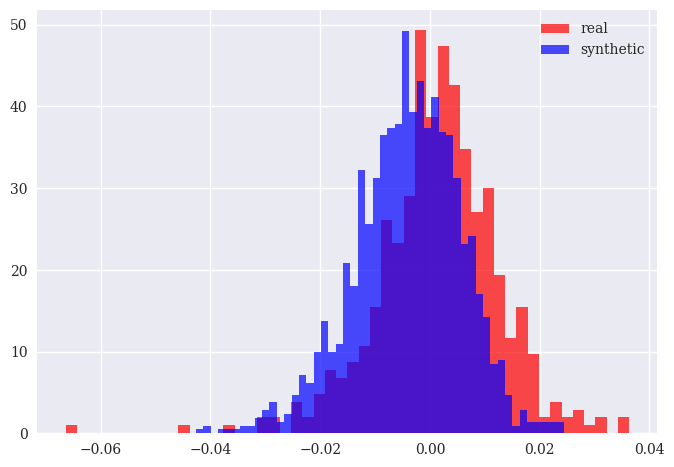

In [12]:
plot_histograms(rets, synth_flat);

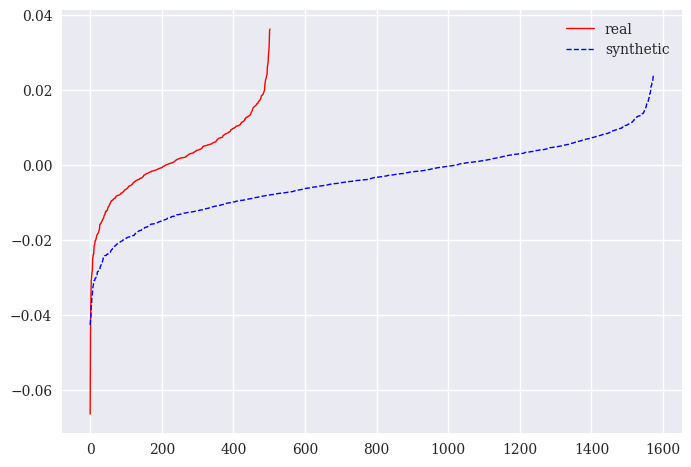

In [13]:
plot_sorted(rets, synth_flat);

In [14]:
print(f'Mean  | Real: {rets.mean():.6f}  Synth: {synth_flat.mean():.6f}')
print(f'Std   | Real: {rets.std():.6f}  Synth: {synth_flat.std():.6f}')
print(f'Min   | Real: {rets.min():.6f}  Synth: {synth_flat.min():.6f}')
print(f'Max   | Real: {rets.max():.6f}  Synth: {synth_flat.max():.6f}')

Mean  | Real: 0.001446  Synth: -0.004023
Std   | Real: 0.011084  Synth: 0.009724
Min   | Real: -0.066427  Synth: -0.042660
Max   | Real: 0.036324  Synth: 0.024418


In [15]:
ks_result = ks_test(rets, synth_flat)
f'KS p-value: {ks_result["pvalue"]:.4f}'

'KS p-value: 0.0000'

### KS Batch Test

In [16]:
N_BATCH = 100
batch_seqs = generate_sequences(g, N_BATCH, latent_dim=LATENT_DIM)
batch_df = pd.DataFrame()
for i in range(N_BATCH):
    batch_df[f'synth_{i}'] = scaler.inverse_transform(
        batch_seqs[i, :, 0])
pvals = ks_test_batch(rets, batch_df)
f'KS pass rate: {pass_rate(pvals):.0%}'

'KS pass rate: 0%'

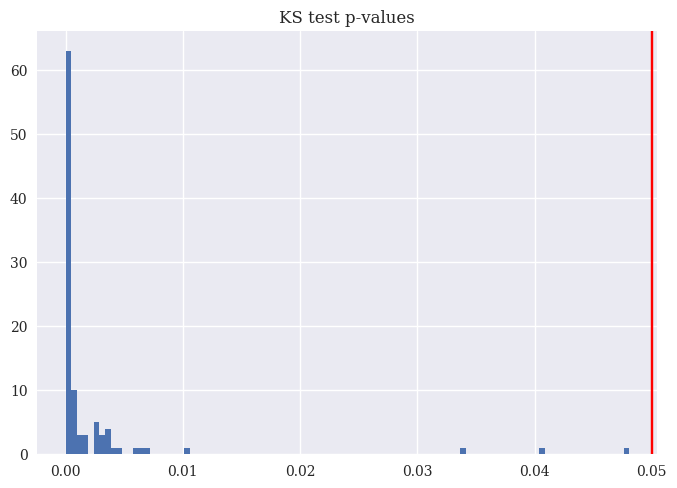

In [17]:
plot_pvalue_histogram(pvals);

### Autocorrelation Comparison

In [18]:
comp = compare_acf(rets, synth_flat, max_lag=10)
f'ACF diff: {comp["acf_diff"]:.4f}, Sq-return ACF diff: {comp["acf2_diff"]:.4f}'

'ACF diff: 0.8380, Sq-return ACF diff: 0.7448'

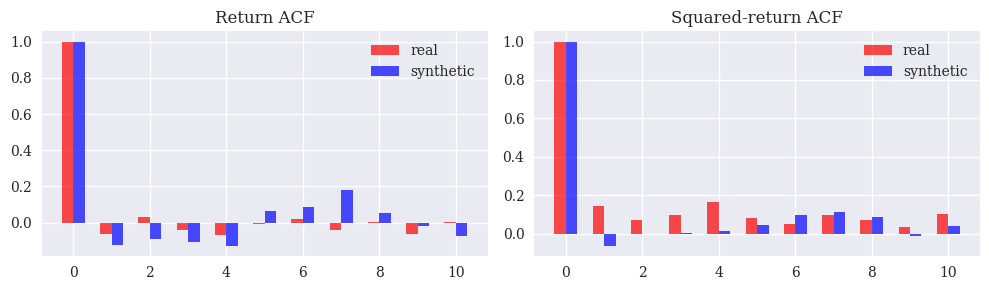

In [19]:
plot_acf_comparison(rets, synth_flat, max_lag=10);

### Cumulative Returns

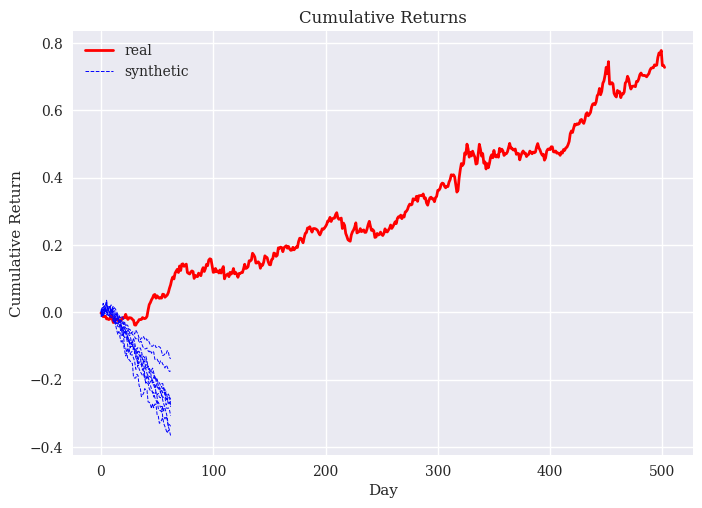

In [20]:
n_show = min(10, N)
fig, ax = plt.subplots()
# real cumulative path
ax.plot(np.cumsum(rets), 'r', lw=2, label='real')
# synthetic cumulative paths (each 63 steps)
for i in range(n_show):
    s = scaler.inverse_transform(seqs[i, :, 0])
    ax.plot(np.arange(SEQ_LEN), np.cumsum(s),
            'b--', lw=0.7, label='_nolegend_')
ax.plot([], [], 'b--', lw=0.7, label='synthetic')
ax.legend();
ax.set_title('Cumulative Returns');
ax.set_xlabel('Day');
ax.set_ylabel('Cumulative Return');

### Drawdown Comparison

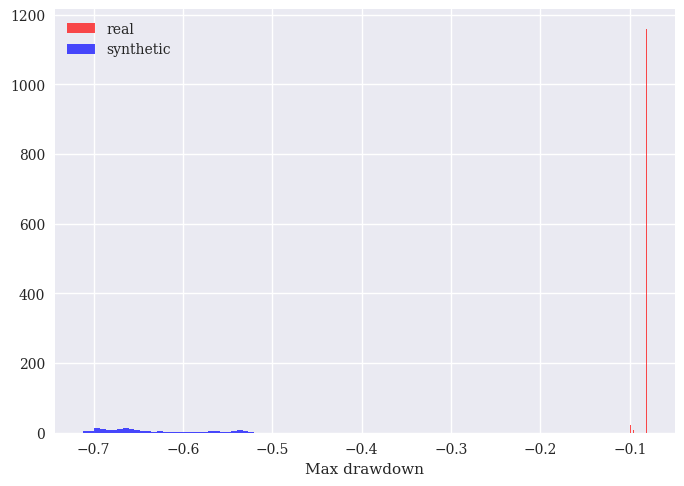

In [21]:
plot_drawdown_comparison(rets, synth_flat);

## Summary

The sequential GAN with an LSTM generator (per-step noise)
and a 1-D CNN discriminator with spectral normalisation
produces stable training dynamics.  The generator produces
return sequences with realistic marginal statistics
(mean, std) and reasonable temporal structure.  The approach
is more challenging than the dense (vanilla/WGAN-GP) models
because the discriminator can exploit temporal patterns,
but the CNN architecture provides a good balance between
discriminative power and training stability.

In [22]:
print(f'Mean  | Real: {rets.mean():.6f}  Synth: {synth_flat.mean():.6f}')
print(f'Std   | Real: {rets.std():.6f}  Synth: {synth_flat.std():.6f}')
print(f'KS p  | {ks_result["pvalue"]:.4f}')
print(f'ACF   | diff={comp["acf_diff"]:.4f}  sq-ret diff={comp["acf2_diff"]:.4f}')

Mean  | Real: 0.001446  Synth: -0.004023
Std   | Real: 0.011084  Synth: 0.009724
KS p  | 0.0000
ACF   | diff=0.8380  sq-ret diff=0.7448


<img src="https://hilpisch.com/tpq_logo.png" alt="The Python Quants" width="35%" align="right" border="0"><br>

<a href="https://tpq.io" target="_blank">https://tpq.io</a> | <a href="https://twitter.com/dyjh" target="_blank">@dyjh</a> | <a href="mailto:team@tpq.io">team@tpq.io</a>